# Sales Data Analysis

### Import Libraries

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


### Load dataset

In [100]:
# Define project paths
PROJECT_DIR = Path.cwd().parent

DATA_PATH = PROJECT_DIR / "data" / "Superstore.csv"

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"

# Create figures directory if it does not exist
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH, encoding="latin1")

print("Dataset loaded successfully")

Dataset loaded successfully


### Understand the dataset

#### First five rows

In [101]:
df.head(1)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91


#### Last five rows

In [102]:
df.tail(1)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9993,9994,CA-2017-119914,5/4/2017,5/9/2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,California,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.16,2,0.00,72.95


##### Number of rows and columns


In [103]:
df.shape

(9994, 21)

#### Data types and non-null counts


In [104]:
df.info()
# df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

#### Statistical summary


In [105]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,"4,997.50","55,190.38",229.86,3.79,0.16,28.66
std,"2,885.16","32,063.69",623.25,2.23,0.21,234.26
min,1.00,"1,040.00",0.44,1.00,0.00,"-6,599.98"
25%,"2,499.25","23,223.00",17.28,2.00,0.00,1.73
50%,"4,997.50","56,430.50",54.49,3.00,0.20,8.67
75%,"7,495.75","90,008.00",209.94,5.00,0.20,29.36
max,"9,994.00","99,301.00","22,638.48",14.00,0.80,"8,399.98"


##### Summary of categorical columns


In [106]:
df.describe(include="object")

C:\Users\singh\AppData\Local\Temp\ipykernel_17112\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994
unique,5009,1237,1334,4,793,793,3,1,531,49,4,1862,3,17,1850
top,CA-2017-100111,9/5/2016,12/16/2015,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,38,35,5968,37,37,5191,9994,915,2001,3203,19,6026,1523,48


### Check data quality

#### Check missing values

In [107]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


#### Check duplicate values

In [108]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


#### Check numerical values

In [109]:
numerical_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]

df[numerical_columns].describe()

,Sales,Quantity,Discount,Profit
count,"9,994.00","9,994.00","9,994.00","9,994.00"
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,"-6,599.98"
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,"22,638.48",14.00,0.80,"8,399.98"


#### Check unique values

In [110]:
categorical_columns = [
    "Ship Mode",
    "Segment",
    "Region",
    "Category",
    "Sub-Category"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Ship Mode:
<StringArray>
['Second Class', 'Standard Class', 'First Class', 'Same Day']
Length: 4, dtype: str

Segment:
<StringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str

Region:
<StringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str

Category:
<StringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str

Sub-Category:
<StringArray>
[  'Bookcases',      'Chairs',      'Labels',      'Tables',     'Storage',
 'Furnishings',         'Art',      'Phones',     'Binders',  'Appliances',
       'Paper', 'Accessories',   'Envelopes',   'Fasteners',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str


### Convert date columns

In [111]:
date_columns = ["Order Date", "Ship Date"]

for column in date_columns:
    df[column] = pd.to_datetime(
        df[column],
        errors="coerce"
    )
print(df[date_columns].isnull().sum())

Order Date    0
Ship Date     0
dtype: int64


#### Calculating shipping days 


In [112]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df[["Order Date", "Ship Date", "Shipping Days"]].head(15)

,Order Date,Ship Date,Shipping Days
0,2016-11-08,2016-11-11,3
1,2016-11-08,2016-11-11,3
2,2016-06-12,2016-06-16,4
3,2015-10-11,2015-10-18,7
4,2015-10-11,2015-10-18,7
5,2014-06-09,2014-06-14,5
6,2014-06-09,2014-06-14,5
7,2014-06-09,2014-06-14,5
8,2014-06-09,2014-06-14,5
9,2014-06-09,2014-06-14,5


### Create useful features
Its is part of feature engineering by creating new columns from existing information to make analysis easier.

#### Time features

In [113]:
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Order Quarter"] = df["Order Date"].dt.quarter

print(df[["Order Date", "Order Year", "Order Month", "Month Name", "Order Quarter"]].head(1))

  Order Date  Order Year  Order Month Month Name  Order Quarter
0 2016-11-08        2016           11   November              4


#### Calculate profit margin

In [114]:
df["Profit Margin"] = np.where(
    df["Sales"] != 0,
    (df["Profit"] / df["Sales"]) * 100,
    np.nan
)
print(df[["Sales", "Profit", "Profit Margin"]].head(1))

   Sales  Profit  Profit Margin
0 261.96   41.91          16.00


#### Calculate sales per unit

In [115]:
df["Sales Per Unit"] = np.where(
    df["Quantity"] != 0,
    df["Sales"] / df["Quantity"],
    np.nan
)
print(df[["Quantity", "Sales", "Sales Per Unit"]].head(1))

   Quantity  Sales  Sales Per Unit
0         2 261.96          130.98


#### Add profitable / loss-making label

In [116]:
df["profit_status"] = np.where(
   df["Profit"] > 0,
   "Profitable",
    "Loss"
)
print(df[["Profit" , "profit_status"]].head(1))

   Profit profit_status
0   41.91    Profitable


### Calculate key business metrics

#### Business Variables

In [117]:
total_sales = df["Sales"].sum()

print("Total Sales:", total_sales)
total_profit = df["Profit"].sum()

print("Total Profit:", total_profit)
total_quantity = df["Quantity"].sum()

print("Total Quantity:", total_quantity)
total_orders = df["Order ID"].nunique() # give count of only unique values

print("Total Orders:", total_orders)
total_orders = df["Order ID"].nunique()

print("Total Orders:", total_orders)
total_customers = df["Customer ID"].nunique()

print("Total Customers:", total_customers)
order_sales = df.groupby("Order ID")["Sales"].sum() # splits the order in unique if and return sum of the sales section of the splied table 

average_order_value = order_sales.mean()

print("Average Order Value:", average_order_value)
profit_margin = (
    total_profit / total_sales
) * 100 if total_sales != 0 else np.nan

print("Profit Margin:", profit_margin)


Total Sales: 2297200.8603
Total Profit: 286397.0217
Total Quantity: 37873
Total Orders: 5009
Total Orders: 5009
Total Customers: 793
Average Order Value: 458.61466566180883
Profit Margin: 12.467217240315605


### Creating a KPI summary

In [118]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Total Quantity",
        "Average Order Value",
        "Profit Margin (%)"
    ],

    "Value": [
        total_sales,
        total_profit,
        total_orders,
        total_customers,
        total_quantity,
        average_order_value,
        profit_margin
    ]
})

kpi_summary

,Metric,Value
0,Total Sales,"2,297,200.86"
1,Total Profit,"286,397.02"
2,Total Orders,"5,009.00"
3,Total Customers,793.00
4,Total Quantity,"37,873.00"
5,Average Order Value,458.61
6,Profit Margin (%),12.47


### Sales analysis

In [119]:
sales_by_category = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_category

Category
Technology        836,154.03
Furniture         741,999.80
Office Supplies   719,047.03
Name: Sales, dtype: float64

In [120]:
profit_by_category = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

profit_by_category

Category
Technology        145,454.95
Office Supplies   122,490.80
Furniture          18,451.27
Name: Profit, dtype: float64

In [121]:
profit_by_subcategory = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

profit_by_subcategory

Sub-Category
Copiers        55,617.82
Phones         44,515.73
Accessories    41,936.64
Paper          34,053.57
Binders        30,221.76
Chairs         26,590.17
Storage        21,278.83
Appliances     18,138.01
Furnishings    13,059.14
Envelopes       6,964.18
Art             6,527.79
Labels          5,546.25
Machines        3,384.76
Fasteners         949.52
Supplies       -1,189.10
Bookcases      -3,472.56
Tables        -17,725.48
Name: Profit, dtype: float64

In [122]:
monthly_sales = (
    df.groupby(df["Order Month"])["Sales"]
    .sum()
)
#(df["Order Date"].dt.to_period("M"))
#df["Order Date"].dt.month
monthly_sales.head()

Order Month
1    94,924.84
2    59,751.25
3   205,005.49
4   137,762.13
5   155,028.81
Name: Sales, dtype: float64

In [123]:
sales_by_segment = (
    df.groupby("Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_segment

Segment
Consumer      1,161,401.34
Corporate       706,146.37
Home Office     429,653.15
Name: Sales, dtype: float64

In [124]:
sales_by_region = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_region

Region
West      725,457.82
East      678,781.24
Central   501,239.89
South     391,721.91
Name: Sales, dtype: float64

In [125]:
discount_profit = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean")
)

discount_profit

,Total_Sales,Total_Profit,Average_Profit
Discount,,,
0.00,"1,087,908.47","320,987.60",66.90
0.10,"54,369.35","9,029.18",96.06
0.15,"27,558.52","1,418.99",27.29
0.20,"764,594.37","90,337.31",24.70
0.30,"103,226.65","-10,369.28",-45.68
0.32,"14,493.46","-2,391.14",-88.56
0.40,"116,417.78","-23,057.05",-111.93
0.45,"5,484.97","-2,493.11",-226.65
0.50,"58,918.54","-20,506.43",-310.70


### Create visualizations

#### Monthly sales trend – Line chart

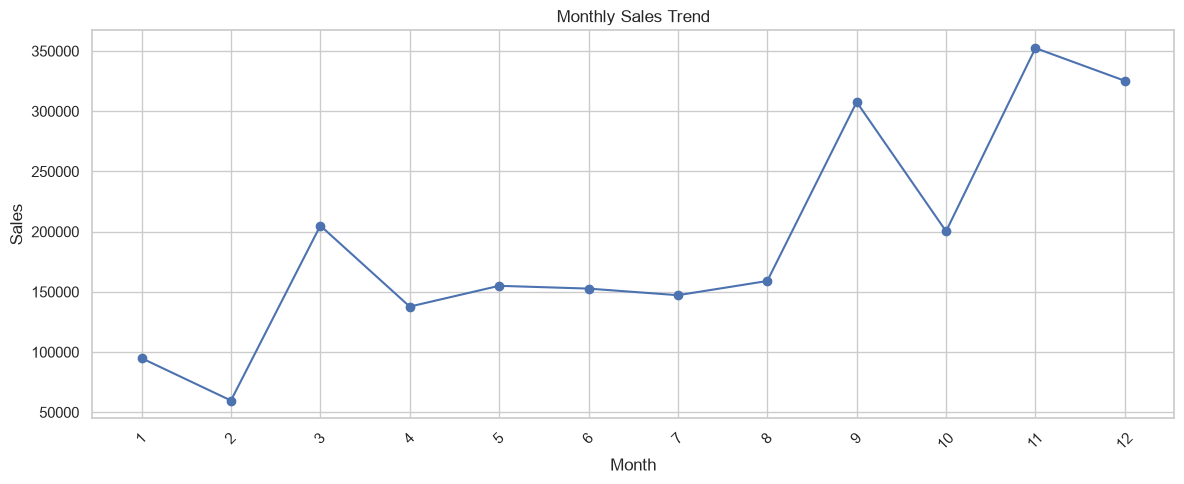

In [126]:
plt.figure(figsize=(12, 5))

monthly_sales.index = monthly_sales.index.astype(str)

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monthly_sales_trend.png",
    dpi=300
)

plt.show()

#### Sales by category – Bar chart

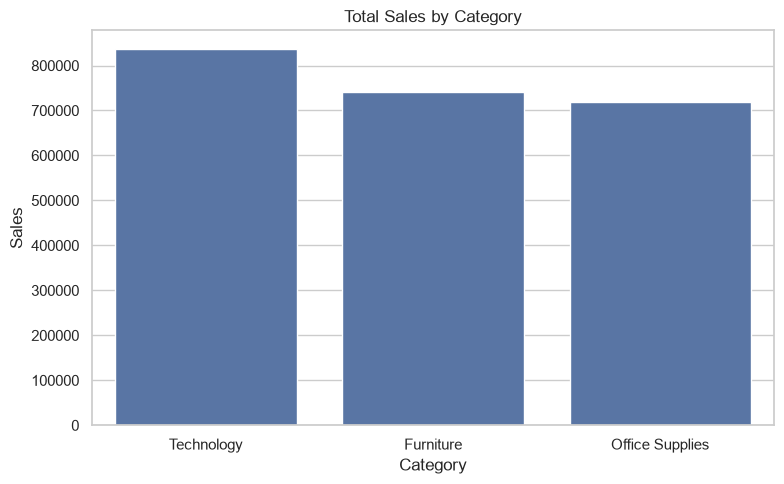

In [127]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sales_by_category.index,
    y=sales_by_category.values
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sales_by_category.png",
    dpi=300
)

plt.show()

Sales by region – Bar chart

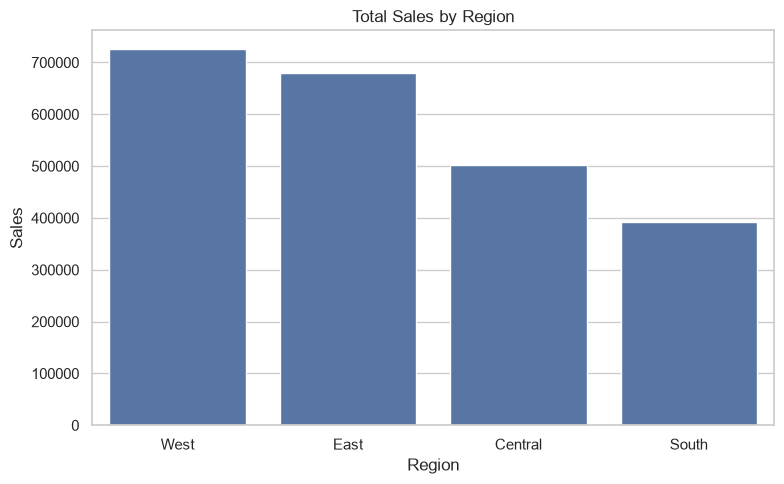

In [128]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sales_by_region.index,
    y=sales_by_region.values
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sales_by_region.png",
    dpi=300
)

plt.show()

#### Profit by category – Bar chart

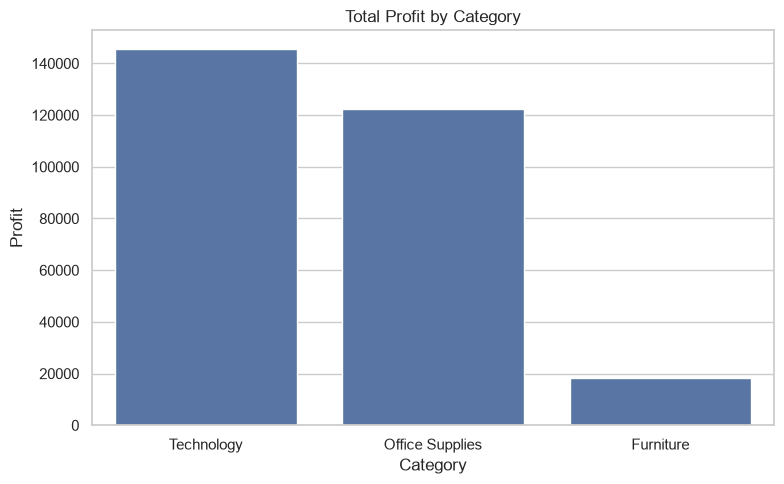

In [129]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=profit_by_category.index,
    y=profit_by_category.values
)

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "profit_by_category.png",
    dpi=300
)

plt.show()

#### Discount vs profit – Scatter plot

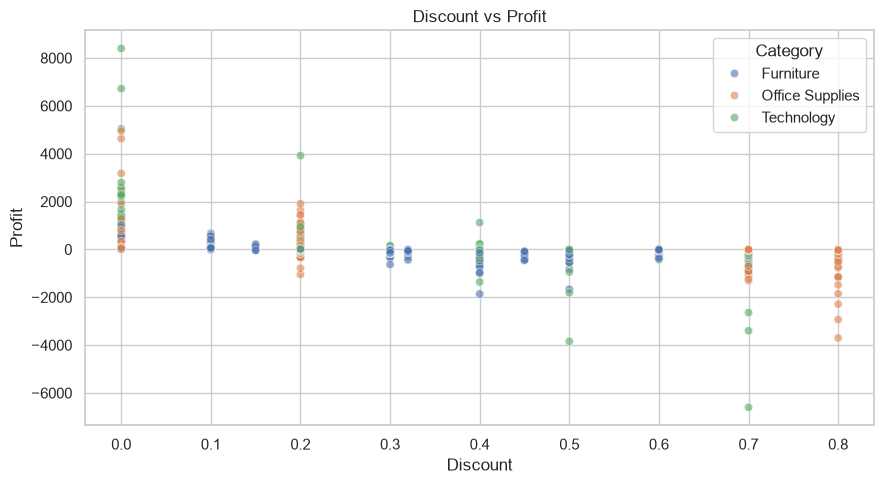

In [130]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "discount_vs_profit.png",
    dpi=300
)

plt.show()

#### Correlation heatmap

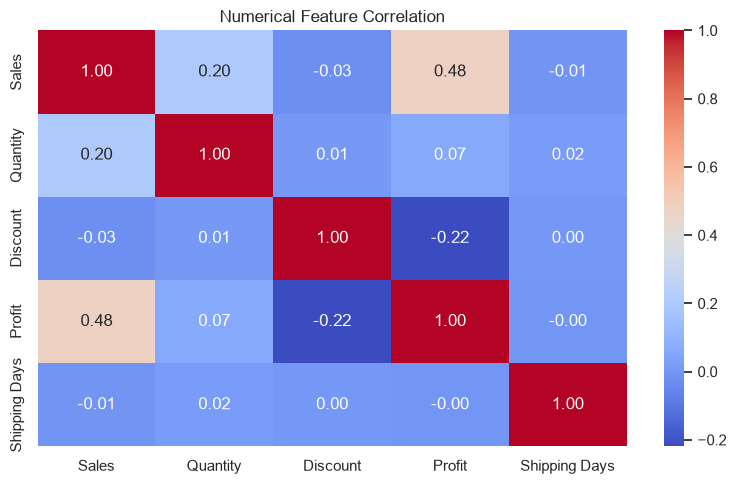

In [131]:
plt.figure(figsize=(8, 5))

correlation = df[
    ["Sales", "Quantity", "Discount", "Profit", "Shipping Days"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=300
)

plt.show()